## ![](https://ga-dash.s3.amazonaws.com/production/assets/logo-9f88ae6c9c3871690e33280fcf557f33.png) Convolutional Neural Networks

**By the end of the lesson, you should be able to:**
- Identify use cases for convolutional neural networks and when they are superior to other neural networks.
- Describe convolutional and pooling layers.
- Define padding and filters.
- Fit CNNs in Keras.

In [1]:
# Import libraries and modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.datasets import mnist, cifar10

In [2]:
# Load pre-shuffled MNIST data into train and test sets
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [3]:
# 3 dimensional data?!
X_train.shape

(60000, 28, 28)

In [4]:
# Check one value of X_train.
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

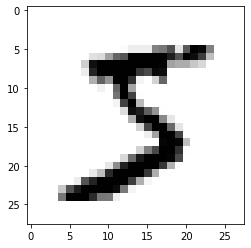

In [5]:
plt.imshow(X_train[0], cmap='binary');

In [6]:
# It's typical to minmax scale data like this. Fortunately, it's just as easy as
# dividing by the maximal value
X_train = X_train / 255
X_test = X_test / 255

In [7]:
# Image data are actually 3-dimensional, where the 3rd data is reserved for 
# the RGB color channel. Our data is only black and white, but we still need to add
# a 3rd dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

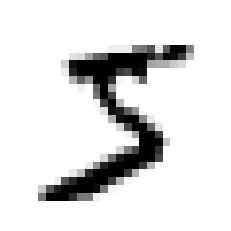

In [8]:
# See? Same.
plt.axis('off')
plt.imshow(X_train[0], cmap='binary');

In [9]:
# Let's jump right in! We'll fit a CNN
# Recall an earlier benchmark: In our SVM lesson, we used
# a simpler version of this data and achieved a test score of 98.8%

model = Sequential()

# Make a convolutional layer with 32 filters.
model.add(Conv2D(32, 3, activation='relu', input_shape=(28, 28, 1)))

# MaxPool the results (basically a requirement)
model.add(MaxPooling2D(2))

# Let's add another convolution block
model.add(Conv2D(64, 3, activation='relu'))
model.add(MaxPooling2D(2))

# Finally, flatten the output and make a predictions through a dense layer.
model.add(Flatten())
model.add(Dense(10, activation='softmax'))

In [10]:
# Look at them layers!
model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d (Conv2D)              (None, 26, 26, 32)        320       
_________________________________________________________________
max_pooling2d (MaxPooling2D) (None, 13, 13, 32)        0         
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 11, 11, 64)        18496     
_________________________________________________________________
max_pooling2d_1 (MaxPooling2 (None, 5, 5, 64)          0         
_________________________________________________________________
flatten (Flatten)            (None, 1600)              0         
_________________________________________________________________
dense (Dense)                (None, 10)                16010     
Total params: 34,826
Trainable params: 34,826
Non-trainable params: 0
____________________________________________________

In [11]:
# Compile
model.compile(
    loss='sparse_categorical_crossentropy', 
    optimizer='rmsprop',
    metrics=['acc']
)

In [12]:
# Fit!
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    batch_size=128,
    epochs=10
)

Epoch 1/10
469/469 [==============================] - 11s 23ms/step - loss: 0.2388 - acc: 0.9315 - val_loss: 0.0808 - val_acc: 0.9750
Epoch 2/10
469/469 [==============================] - 10s 22ms/step - loss: 0.0759 - acc: 0.9772 - val_loss: 0.0475 - val_acc: 0.9847
Epoch 3/10
469/469 [==============================] - 10s 22ms/step - loss: 0.0545 - acc: 0.9833 - val_loss: 0.0431 - val_acc: 0.9856
Epoch 4/10
469/469 [==============================] - 10s 22ms/step - loss: 0.0433 - acc: 0.9865 - val_loss: 0.0383 - val_acc: 0.9868
Epoch 5/10
469/469 [==============================] - 10s 22ms/step - loss: 0.0362 - acc: 0.9892 - val_loss: 0.0336 - val_acc: 0.9882
Epoch 6/10
469/469 [==============================] - 10s 22ms/step - loss: 0.0316 - acc: 0.9905 - val_loss: 0.0344 - val_acc: 0.9891
Epoch 7/10
469/469 [==============================] - 10s 22ms/step - loss: 0.0277 - acc: 0.9915 - val_loss: 0.0335 - val_acc: 0.9886
Epoch 8/10
469/469 [==============================] - 10s 22ms

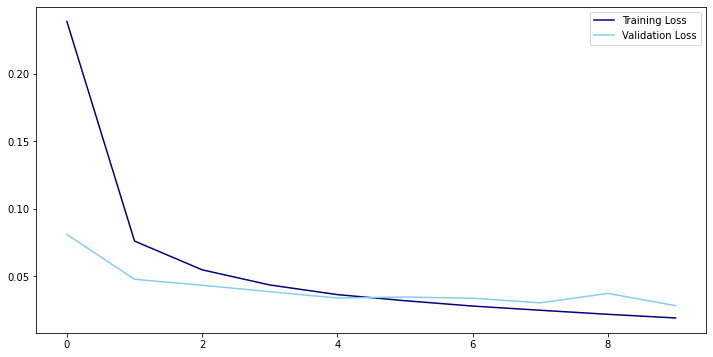

In [13]:
# Check out the plot of loss vs epoch. How's our model?
plt.figure(figsize=(12, 6))
plt.plot(history.history['loss'], c='navy', label='Training Loss')
plt.plot(history.history['val_loss'], c='skyblue', label='Validation Loss')
plt.legend();

In [14]:
# What's our model accuracy?
model.evaluate(X_test, y_test)

313/313 [==============================] - 1s 3ms/step - loss: 0.0280 - acc: 0.9909


[0.02795661985874176, 0.9908999800682068]

In [15]:
y_pred = np.argmax(model.predict(X_test), axis=1)
y_pred

array([7, 2, 1, ..., 4, 5, 6])

In [16]:
y_test

array([7, 2, 1, ..., 4, 5, 6], dtype=uint8)

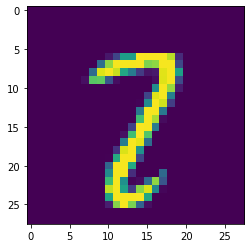

We thought = 7, but really 2


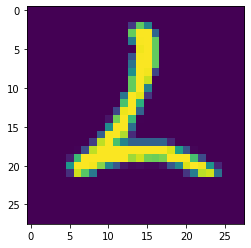

We thought = 1, but really 2


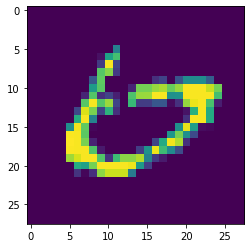

We thought = 0, but really 6


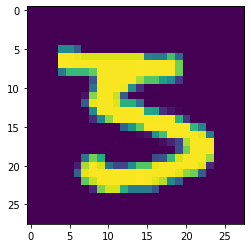

We thought = 5, but really 3


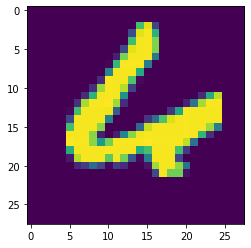

We thought = 4, but really 6


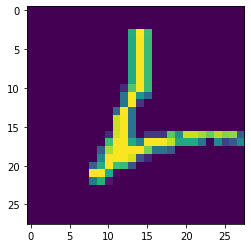

We thought = 4, but really 2


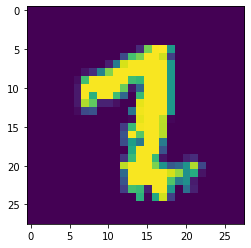

We thought = 1, but really 2


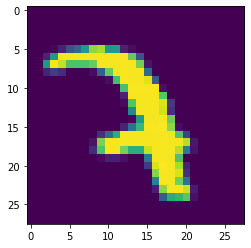

We thought = 3, but really 7


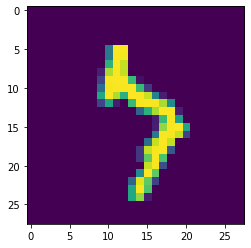

We thought = 4, but really 7


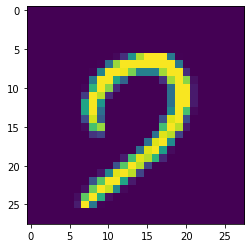

We thought = 9, but really 7


In [17]:
wrong_ix = np.where(y_pred != y_test)[0]
for i in wrong_ix[:10]:
    plt.clf()
    plt.imshow(X_test[i])
    plt.show()
    pred = y_pred[i]
    truth = y_test[i]
    print(f'We thought = {pred}, but really {truth}')

# Let's Try Another Dataset!
We'll use the famous CIFAR10 dataset. You can read a little about it [here](https://keras.io/api/datasets/cifar10/).

In [18]:
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

In [19]:
X_train.shape

(50000, 32, 32, 3)

In [20]:
y_train.shape

(50000, 1)

In [21]:
# The red channel of image 0
X_train[0, :, :, 0]

array([[ 59,  43,  50, ..., 158, 152, 148],
       [ 16,   0,  18, ..., 123, 119, 122],
       [ 25,  16,  49, ..., 118, 120, 109],
       ...,
       [208, 201, 198, ..., 160,  56,  53],
       [180, 173, 186, ..., 184,  97,  83],
       [177, 168, 179, ..., 216, 151, 123]], dtype=uint8)

Category: [6]


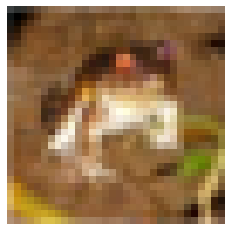

In [22]:
# Nice... frog?
i = 0
print(f"Category: {y_train[i]}")
plt.axis('off')
plt.imshow(X_train[i]);

In [23]:
# Let's scale our Xs again
X_train = X_train / 255
X_test = X_test / 255

In [24]:
# Let's fit a model! Gotta be a big one.
model = Sequential()

model.add(Conv2D(64, 3, activation='relu', input_shape=(32, 32, 3)))
model.add(MaxPooling2D(2))
model.add(Conv2D(128, 3, activation='relu'))
model.add(MaxPooling2D(2))
model.add(Flatten())
model.add(Dense(64, activation='relu'))
model.add(Dense(10, activation='softmax'))

In [25]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_2 (Conv2D)            (None, 30, 30, 64)        1792      
_________________________________________________________________
max_pooling2d_2 (MaxPooling2 (None, 15, 15, 64)        0         
_________________________________________________________________
conv2d_3 (Conv2D)            (None, 13, 13, 128)       73856     
_________________________________________________________________
max_pooling2d_3 (MaxPooling2 (None, 6, 6, 128)         0         
_________________________________________________________________
flatten_1 (Flatten)          (None, 4608)              0         
_________________________________________________________________
dense_1 (Dense)              (None, 64)                294976    
_________________________________________________________________
dense_2 (Dense)              (None, 10)               

In [26]:
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='rmsprop',
    metrics=['acc']
)

In [27]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    batch_size=32,
    epochs=10
)

Epoch 1/10
1563/1563 [==============================] - 35s 22ms/step - loss: 1.4434 - acc: 0.4830 - val_loss: 1.1986 - val_acc: 0.5887
Epoch 2/10
1563/1563 [==============================] - 34s 22ms/step - loss: 1.0396 - acc: 0.6391 - val_loss: 1.1174 - val_acc: 0.6209
Epoch 3/10
1563/1563 [==============================] - 34s 22ms/step - loss: 0.8876 - acc: 0.6930 - val_loss: 0.9803 - val_acc: 0.6628
Epoch 4/10
1563/1563 [==============================] - 34s 22ms/step - loss: 0.7812 - acc: 0.7325 - val_loss: 0.9499 - val_acc: 0.6844
Epoch 5/10
1563/1563 [==============================] - 35s 22ms/step - loss: 0.7039 - acc: 0.7572 - val_loss: 0.8956 - val_acc: 0.7036
Epoch 6/10
1563/1563 [==============================] - 34s 22ms/step - loss: 0.6352 - acc: 0.7827 - val_loss: 0.9504 - val_acc: 0.7006
Epoch 7/10
1563/1563 [==============================] - 34s 22ms/step - loss: 0.5755 - acc: 0.8034 - val_loss: 1.1159 - val_acc: 0.6646
Epoch 8/10
1563/1563 [==========================

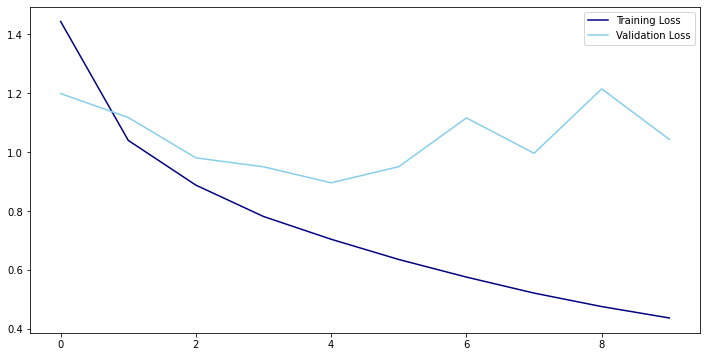

In [28]:
# Check out the plot of loss vs epoch. How's our model?
plt.figure(figsize=(12, 6))
plt.plot(history.history['loss'], c='navy', label='Training Loss')
plt.plot(history.history['val_loss'], c='skyblue', label='Validation Loss')
plt.legend();

# Summary
CNNs are cool! They're the first time we're able to _really_ work with image data. Parting thoughts from this lesson:
* Two fundamental truths of image recognition are that images are inherently **translation invariant** and **spatially hierarchical**.
    * Translation invariant = We still recognize things when they move over a little bit.
    * We recognize complex images as being made up of smaller features (edges, corners, etc)
* CNNs are engeineered to incorporate the two fundamental truths
* Generally the format of a CNN is as follows:
    * Convolutional layer
    * MaxPool layer
    * Repeat the above two steps once or twice more
    * Flatten the weights into a single vector
    * A dense layer or two before the output